# Hour 2 · Compare the room

Every finished hour-2 job appends one row to the shared scoreboard
(`/leonardo_work/tra26_aiwcas/aiwcas26_scoreboard/scoreboard.csv`) and copies its loss curves next to it
(see `scripts/scoreboard.py`). This notebook reads only those shared files, so it shows **everybody's** runs, not
just yours. Re-run it (*Run → Run All Cells*) whenever new runs come in.

The options train different things with different losses (MSE, afCRPS, an MSE over Italy only for the LAM of
option B1, different variable sets), so raw loss values are **not** comparable across the room. We therefore look at three things:

1. **Did everybody learn, and how fast?** Training loss divided by its own starting value, against step and
   against wall time (the wall-time axis includes the ~3–4 min of job startup, which is the real cost of a short job).
2. **Who did better, like for like?** Raw validation loss, but only inside groups that share the loss, the
   output variables and the rollout.
3. **What did it cost?** Parameters, seconds per step and peak GPU memory per run.

In [1]:
import os
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SCOREBOARD_DIR = Path(os.environ.get("SCOREBOARD_DIR", "/leonardo_work/tra26_aiwcas/aiwcas26_scoreboard"))
EMA = 0.6          # smoothing of the training curves: 0 = raw, 0.9 = very smooth
ONLY_ME = False    # True: show only your own runs

# Reference categorical palette, fixed order: colour follows the option, never its rank.
OPTION_COLORS = {"0": "#2a78d6", "A": "#eb6834", "C": "#1baf7a", "B1": "#eda100"}
OPTION_NAMES = {"0": "0 · make the base yours", "A": "A · processor zoo", "C": "C · ensemble CRPS", "B1": "B1 · Italy LAM"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "lines.linewidth": 1.6, "legend.frameon": False, "font.size": 10,
})

csv_path = SCOREBOARD_DIR / "scoreboard.csv"
board = pd.read_csv(csv_path, dtype={"option": str, "job_id": str}) if csv_path.is_file() else pd.DataFrame()
if ONLY_ME and len(board):
    board = board[board.user == os.environ.get("USER")]
board = board.drop_duplicates(subset=["user", "job_id", "mlflow_run_id"], keep="last").reset_index(drop=True)
print(f"{len(board)} run(s) on the scoreboard ({csv_path})")
if board.empty:
    print("Nothing to compare yet: finish a run with scripts/submit.sh, or add one with "
          "`python scripts/scoreboard.py add --job <id>`.")

4 run(s) on the scoreboard (/leonardo_work/tra26_aiwcas/aiwcas26_scoreboard/scoreboard.csv)


In [2]:
def load_curve(row, name):
    path = SCOREBOARD_DIR / str(row.curves_dir) / f"{name}_loss.csv"
    return pd.read_csv(path) if isinstance(row.curves_dir, str) and path.is_file() else pd.DataFrame(columns=["step", "value", "time_s"])

def ema(values, alpha=EMA):
    out, acc = [], None
    for v in values:
        acc = v if acc is None else alpha * acc + (1 - alpha) * v
        out.append(acc)
    return np.array(out)

def label(row):
    return f"{row.user} · {row.run_name}"

curves = {i: (load_curve(r, "train"), load_curve(r, "val")) for i, r in board.iterrows()}

cols = ["user", "option", "run_name", "arch", "loss", "n_params", "s_per_step", "peak_gpu_mem_mib",
        "train_loss_first", "train_loss_last", "loss_ratio", "val_loss_first", "val_loss_last", "startup_s", "train_cmd_wall_s"]
if len(board):
    show = board[[c for c in cols if c in board]].copy()
    show["n_params"] = (show["n_params"] / 1e6).round(2)
    show = show.rename(columns={"n_params": "params (M)", "peak_gpu_mem_mib": "GPU mem (MiB)",
                                "startup_s": "startup (s)", "train_cmd_wall_s": "job (s)"})
    display(show.sort_values(["option", "loss_ratio"]).style.hide(axis="index").format(precision=3))

user,option,run_name,arch,loss,params (M),s_per_step,GPU mem (MiB),train_loss_first,train_loss_last,loss_ratio,val_loss_first,val_loss_last,startup (s),job (s)
a08trd25,0,0-sfc+2lev-ms1-r2-2tx5,GNN,MSE,2.300,0.117,2404,0.105,0.059,0.564,0.101,0.071,286,357
a08trd25,A,A-graphtransformer,GraphTransformer,MSE,2.300,0.103,2308,0.145,0.035,0.245,0.073,0.039,293,366
a08trd25,B1,B1-lam-thin4-tri7,GraphTransformer,MSE(LAM),0.570,0.063,1914,0.510,0.122,0.240,0.141,0.124,307,353
a08trd25,C,C-gt-ens4-afcrps,GraphTransformer,afCRPS(a=0.95),2.300,0.157,4858,0.295,0.097,0.331,0.204,0.106,281,355


## 1 · Did everybody learn? (normalised training loss)

Each curve is a run's training loss divided by its own first logged value (step 10), lightly smoothed.
Below 1 means it learned. Lines are coloured by option. On the right, the grey band is the job startup before the
first logged step (imports, config, data, graph, model): on these short jobs it costs more than the training.

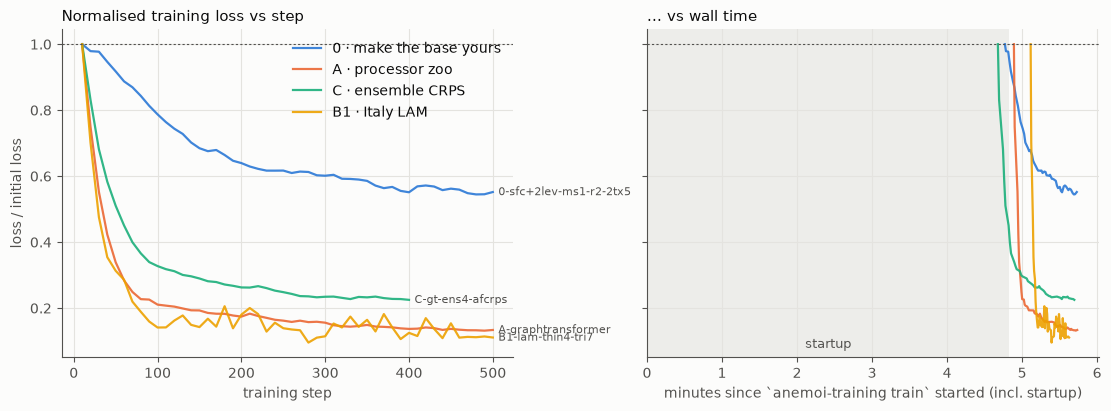

In [3]:
if board.empty:
    print("no runs yet")
else:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained", sharey=True)
    seen, startups = set(), []
    for i, row in board.iterrows():
        tr = curves[i][0]
        if len(tr) == 0:
            continue
        y = ema(tr.value.to_numpy()) / tr.value.iloc[0]
        startups.append(tr.time_s.iloc[0] / 60)
        color = OPTION_COLORS.get(row.option, "#6250d6")
        lab = OPTION_NAMES.get(row.option, row.option) if row.option not in seen else None
        seen.add(row.option)
        ax1.plot(tr.step + 1, y, color=color, alpha=0.9, label=lab)
        ax2.plot(tr.time_s / 60, y, color=color, alpha=0.9)
        if len(board) <= 6:   # direct labels only while there are few lines
            ax1.annotate(row.run_name, (tr.step.iloc[-1] + 1, y[-1]), xytext=(4, 0), textcoords="offset points",
                         va="center", fontsize=8, color=INK2)
    if startups:
        ax2.axvspan(0, np.median(startups), color=GRID, alpha=0.6, lw=0)
        ax2.text(np.median(startups) / 2, 0.02, "startup", transform=ax2.get_xaxis_transform(),
                 ha="center", va="bottom", fontsize=9, color=INK2)
    ax1.axhline(1, color=INK2, lw=0.8, ls=(0, (2, 2)))
    ax2.axhline(1, color=INK2, lw=0.8, ls=(0, (2, 2)))
    ax1.set(xlabel="training step", ylabel="loss / initial loss", title="Normalised training loss vs step")
    ax2.set(xlabel="minutes since `anemoi-training train` started (incl. startup)", title="... vs wall time")
    ax2.set_xlim(left=0)
    ax1.legend(loc="upper right")
    plt.show()

## 2 · Like for like (raw validation loss within comparable groups)

Runs are grouped by `compare_group` = loss function | number of output variables | rollout (option 0 also by its
loss weights). Only inside a group do raw numbers mean "better" or "worse". Option A's architectures all share one
group: that is the point of the zoo. Option B1's loss is marked `MSE(LAM)`: it is computed only on the CERRA points
over Italy (5 output variables), so B1 runs form their own group.

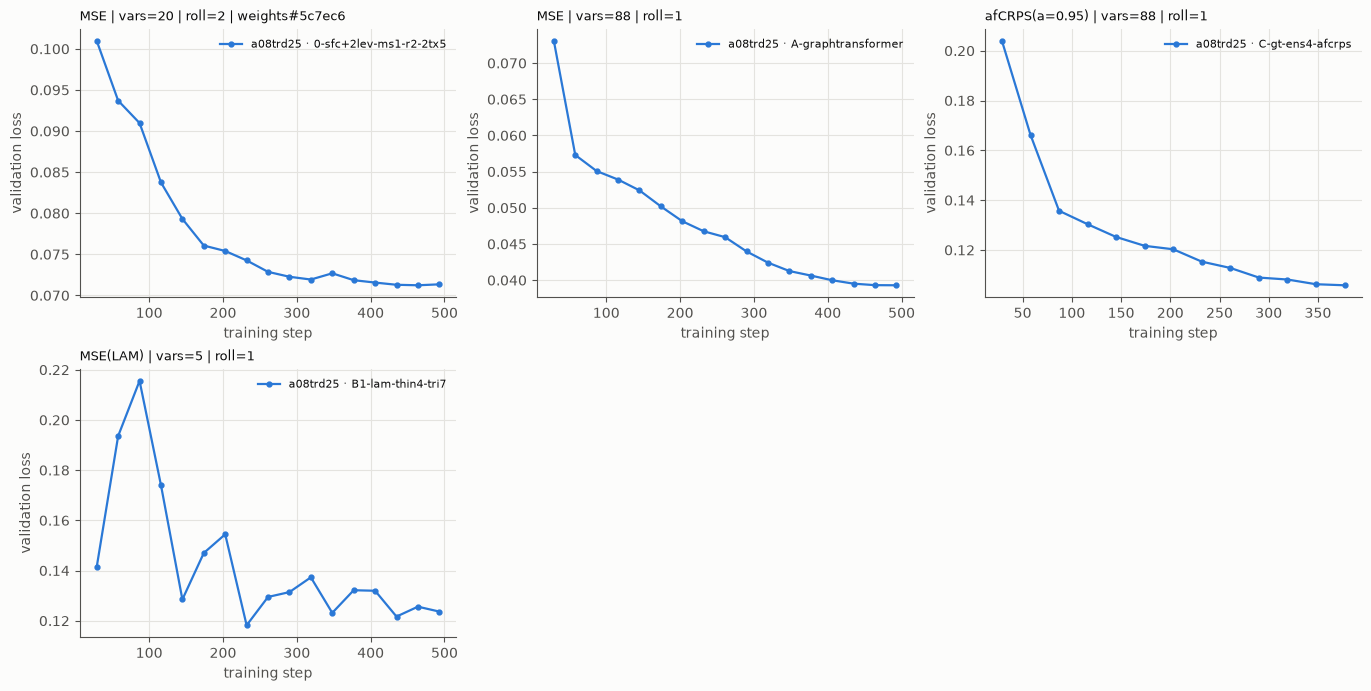

In [4]:
groups = [g for g in board.compare_group.dropna().unique()] if len(board) else []
if not groups:
    print("no runs yet")
else:
    n = len(groups)
    ncol = min(n, 3)
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol + 1, 3.4 * nrow), layout="constrained", squeeze=False)
    for ax, g in zip(axes.flat, groups):
        members = board[board.compare_group == g]
        for k, (i, row) in enumerate(members.iterrows()):
            va = curves[i][1]
            if len(va) == 0:
                continue
            color = SERIES[k] if k < len(SERIES) else "#8a8984"   # >8 runs: fold the rest to grey
            ax.plot(va.step + 1, va.value, "-o", ms=3.5, color=color, label=label(row) if k < len(SERIES) else None)
        ax.set_title(textwrap.fill(g, 48), fontsize=9.5)
        ax.set(xlabel="training step", ylabel="validation loss")
        ax.legend(fontsize=8, loc="upper right")
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    plt.show()

## 3 · What did it cost?

Same order and colours as above (by option). *s/step* is measured between the first and last logged training
step and includes the short validation passes; the job also pays ~3–4 min of imports and setup before step 1.

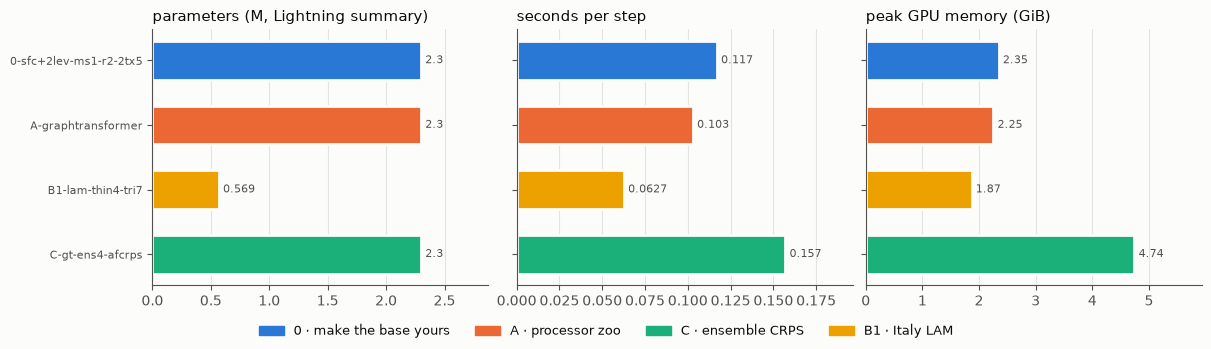

In [5]:
if board.empty:
    print("no runs yet")
else:
    b = board.sort_values(["option", "run_name"]).reset_index(drop=True)
    names = [f"{r.user}\n{r.run_name}" if b.user.nunique() > 1 else r.run_name for r in b.itertuples()]
    colors = [OPTION_COLORS.get(o, "#6250d6") for o in b.option]
    metrics = [("n_params", 1e-6, "parameters (M, Lightning summary)"), ("s_per_step", 1, "seconds per step"),
               ("peak_gpu_mem_mib", 1 / 1024, "peak GPU memory (GiB)")]
    fig, axes = plt.subplots(1, 3, figsize=(12, 0.45 * len(b) + 1.6), layout="constrained", sharey=True)
    y = np.arange(len(b))
    for ax, (col, scale, title) in zip(axes, metrics):
        vals = pd.to_numeric(b[col], errors="coerce") * scale
        ax.barh(y, vals, height=0.6, color=colors, edgecolor=SURFACE, linewidth=2)
        for yi, v in zip(y, vals):
            if np.isfinite(v):
                ax.annotate(f"{v:.3g}", (v, yi), xytext=(3, 0), textcoords="offset points", va="center",
                            fontsize=8, color=INK2)
        ax.set_title(title)
        ax.grid(axis="y", visible=False)
        ax.set_axisbelow(True)
        ax.set_xlim(0, np.nanmax(vals) * 1.25 if np.isfinite(np.nanmax(vals)) else 1)
    axes[0].set_yticks(y, names, fontsize=8)
    axes[0].invert_yaxis()
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for o, c in OPTION_COLORS.items() if o in set(b.option)]
    fig.legend(handles, [OPTION_NAMES[o] for o in OPTION_COLORS if o in set(b.option)], loc="outside lower center",
               ncol=4, fontsize=9)
    plt.show()

### Things to discuss

* **A:** which processor learns fastest per *step*, and per *minute*? Does the point-wise MLP (no neighbours at
  all) plateau higher? That gap is what message passing / attention buys you.
* **0:** fewer output variables or a longer rollout change the loss itself: compare only inside a group.
* **C:** afCRPS is not MSE, so only the normalised plot puts it next to the others. What do 4 members cost
  compared with the deterministic GraphTransformer of option A?
* **B1:** the LAM predicts only Italy, at 22 km, from 5 variables and a 300 km ring of global boundary points.
  Its loss is not comparable with the global options; compare B1 runs with each other (area, thinning, hidden
  resolution). How does its cost per step compare with the global models?
* **Startup:** for these 5-minute jobs most of the wall time is imports and setup, not training.